In [ ]:
import os
from pathlib import Path
import kagglehub

shords_path = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
audio_files_path = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

print(f"shords_dataset: {shords_path}")
print(f"Audio_Files: {audio_files_path}")

# Dont know why but I cant get it to work by just giving the path above, but this works
data_dir = Path('data')
shords_dest = data_dir / 'shords_dataset'
audio_dest  = data_dir / 'Audio_Files'

if not shords_dest.exists():
    shords_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(shords_path, str(shords_dest))

if not audio_dest.exists():
    audio_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(audio_files_path, str(audio_dest))

100%|██████████| 319M/319M [00:02<00:00, 122MB/s]

Extracting files...


100%|██████████| 135M/135M [00:00<00:00, 166MB/s]

Extracting files...


shords_dataset: /root/.cache/kagglehub/datasets/mehanat96/major-vs-minor-guitar-chords/versions/1
Audio_Files: /root/.cache/kagglehub/datasets/deepcontractor/musical-instrument-chord-classification/versions/2


# Windowing Experiment

In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

from features import load_audio, normalize_duration, extract_chroma, extract_mfcc, extract_all_features
from features import extract_mel_spectrogram

import warnings
warnings.filterwarnings('ignore')

### Load audio

In [3]:
SR = 22050
TARGET_DURATION = 2.0

#  Colab
AUDIO_DIR = Path('/content/data/Audio_Files/Audio_Files')
SHORDS_DIR = Path('/content/data/shords_dataset/shords_dataset')

# AUDIO_DIR = Path('../data/Audio_Files')
# SHORDS_DIR = Path('../data/shords_dataset')

def load_raw_audio(data_dir, sr=SR, target_duration=TARGET_DURATION):
    data_dir = Path(data_dir)
    waveforms, labels = [], []
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        for audio_file in sorted(label_dir.iterdir()):
            if audio_file.suffix not in ['.wav', '.mp3', '.flac', '.ogg']:
                continue
            y, _ = load_audio(str(audio_file), sr=sr, target_duration=target_duration)
            waveforms.append(y)
            labels.append(label)
    return waveforms, labels

waveforms_audio, labels_audio = load_raw_audio(AUDIO_DIR)
waveforms_shords, labels_shords = load_raw_audio(SHORDS_DIR)

waveforms = waveforms_audio + waveforms_shords
labels = np.array(labels_audio + labels_shords)

print(f'Audio_Files: {len(waveforms_audio)}, shords_dataset: {len(waveforms_shords)}, total: {len(waveforms)}')
print(f'Classes: {dict(zip(*np.unique(labels, return_counts=True)))}')

Audio_Files: 859, shords_dataset: 502, total: 1361
Classes: {np.str_('Major'): np.int64(752), np.str_('Minor'): np.int64(609)}


### Windowed feature extraction

In [4]:
def extract_windowed_features(y, sr, window_sec, overlap=0.5):
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))

    window_features = []
    start = 0
    while start + window_samples <= len(y):
        segment = y[start:start + window_samples]
        feat = np.concatenate([extract_chroma(segment, sr), extract_mfcc(segment, sr)])
        window_features.append(feat)
        start += hop_samples

    if len(window_features) == 0:
        window_features.append(np.concatenate([extract_chroma(y, sr), extract_mfcc(y, sr)]))

    window_features = np.array(window_features)
    return np.concatenate([np.mean(window_features, axis=0), np.std(window_features, axis=0)])


def build_feature_matrix(waveforms, sr, window_sec, overlap=0.5):
    return np.array([extract_windowed_features(y, sr, window_sec, overlap) for y in waveforms])


def build_baseline_features(waveforms, sr):
    return np.array([extract_all_features(y, sr) for y in waveforms])


WINDOW_CONFIGS = {
    'Baseline (2.0s)': None,
    '1.0s windows': 1.0,
    '0.5s windows': 0.5,
    '0.25s windows': 0.25,
}

for name, w in WINDOW_CONFIGS.items():
    if w is None:
        print(f'{name}')
    else:
        n_win = int((TARGET_DURATION - w) / (w * 0.5)) + 1
        print(f'{name}: {n_win} windows')

Baseline (2.0s)
1.0s windows: 3 windows
0.5s windows: 7 windows
0.25s windows: 15 windows


### Build feature matrices for different windows

In [5]:
feature_sets = {}
for name, window_sec in WINDOW_CONFIGS.items():
    if window_sec is None:
        X = build_baseline_features(waveforms, SR)
    else:
        X = build_feature_matrix(waveforms, SR, window_sec)
    feature_sets[name] = X
    print(f'{name}: {X.shape}')

le = LabelEncoder()
y = le.fit_transform(labels)
print(f'Classes: {le.classes_}')

Baseline (2.0s): (1361, 25)
1.0s windows: (1361, 50)
0.5s windows: (1361, 50)
0.25s windows: (1361, 50)
Classes: ['Major' 'Minor']


### Cross-validation

In [6]:
MODELS = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM':           SVC(kernel='rbf', random_state=42),
    'KNN':           KNeighborsClassifier(n_neighbors=5),
    'Logistic Reg.': LogisticRegression(max_iter=1000, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for window_name, X in feature_sets.items():
    for model_name, model in MODELS.items():
        pipe = make_pipeline(StandardScaler(), model)
        scores = cross_val_score(pipe, X, y, cv=cv, scoring='f1_weighted')
        results.append({
            'Window': window_name, 'Model': model_name,
            'F1': scores.mean(), 'Std': scores.std(), 'Folds': scores.tolist(),
        })
        print(f'{window_name:20s} | {model_name:14s} | {scores.mean():.4f} ± {scores.std():.4f}')

results_df = pd.DataFrame(results)

Baseline (2.0s)      | Random Forest  | 0.7790 ± 0.0235
Baseline (2.0s)      | SVM            | 0.6803 ± 0.0191
Baseline (2.0s)      | KNN            | 0.6450 ± 0.0152
Baseline (2.0s)      | Logistic Reg.  | 0.6035 ± 0.0178
1.0s windows         | Random Forest  | 0.7614 ± 0.0245
1.0s windows         | SVM            | 0.7133 ± 0.0203
1.0s windows         | KNN            | 0.6769 ± 0.0183
1.0s windows         | Logistic Reg.  | 0.6029 ± 0.0108
0.5s windows         | Random Forest  | 0.7613 ± 0.0240
0.5s windows         | SVM            | 0.6939 ± 0.0081
0.5s windows         | KNN            | 0.6637 ± 0.0185
0.5s windows         | Logistic Reg.  | 0.6150 ± 0.0142
0.25s windows        | Random Forest  | 0.7632 ± 0.0111
0.25s windows        | SVM            | 0.7062 ± 0.0166
0.25s windows        | KNN            | 0.6686 ± 0.0177
0.25s windows        | Logistic Reg.  | 0.6227 ± 0.0151


## Results

In [7]:
pivot = results_df.pivot_table(index='Window', columns='Model', values='F1')
pivot = pivot.reindex(WINDOW_CONFIGS.keys())

display(pivot.style.format('{:.4f}').background_gradient(axis=None))

Model,KNN,Logistic Reg.,Random Forest,SVM
Window,,,,
Baseline (2.0s),0.6450,0.6035,0.7790,0.6803
1.0s windows,0.6769,0.6029,0.7614,0.7133
0.5s windows,0.6637,0.6150,0.7613,0.6939
0.25s windows,0.6686,0.6227,0.7632,0.7062


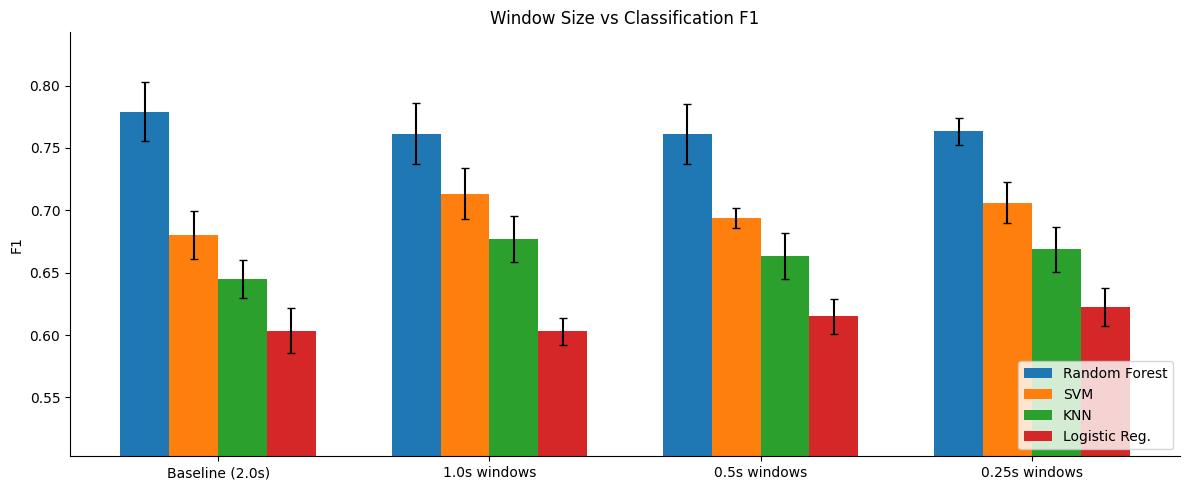

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

window_names = list(WINDOW_CONFIGS.keys())
model_names = list(MODELS.keys())
x = np.arange(len(window_names))
width = 0.18

for i, model_name in enumerate(model_names):
    means = [results_df[(results_df['Window'] == w) & (results_df['Model'] == model_name)]['F1'].values[0]
             for w in window_names]
    stds  = [results_df[(results_df['Window'] == w) & (results_df['Model'] == model_name)]['Std'].values[0]
             for w in window_names]
    ax.bar(x + i * width, means, width, yerr=stds, label=model_name, capsize=3)

ax.set_xticks(x + width * (len(model_names) - 1) / 2)
ax.set_xticklabels(window_names)
ax.set_ylabel('F1')
ax.set_title('Window Size vs Classification F1')
ax.set_ylim(bottom=max(0, results_df['F1'].min() - 0.1))
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

### Improvement over baseline

In [9]:
baseline = results_df[results_df['Window'] == 'Baseline (2.0s)'].set_index('Model')['F1']

for model_name in model_names:
    base = baseline[model_name]
    print(f'{model_name}:')
    for window_name in window_names[1:]:
        f1 = results_df[(results_df['Window'] == window_name) & (results_df['Model'] == model_name)]['F1'].values[0]
        delta = f1 - base
        print(f'  {window_name:18s}  {f1:.4f}  ({delta:+.4f})')
    print()

Random Forest:
  1.0s windows        0.7614  (-0.0176)
  0.5s windows        0.7613  (-0.0177)
  0.25s windows       0.7632  (-0.0158)

SVM:
  1.0s windows        0.7133  (+0.0330)
  0.5s windows        0.6939  (+0.0136)
  0.25s windows       0.7062  (+0.0259)

KNN:
  1.0s windows        0.6769  (+0.0319)
  0.5s windows        0.6637  (+0.0187)
  0.25s windows       0.6686  (+0.0236)

Logistic Reg.:
  1.0s windows        0.6029  (-0.0007)
  0.5s windows        0.6150  (+0.0115)
  0.25s windows       0.6227  (+0.0192)



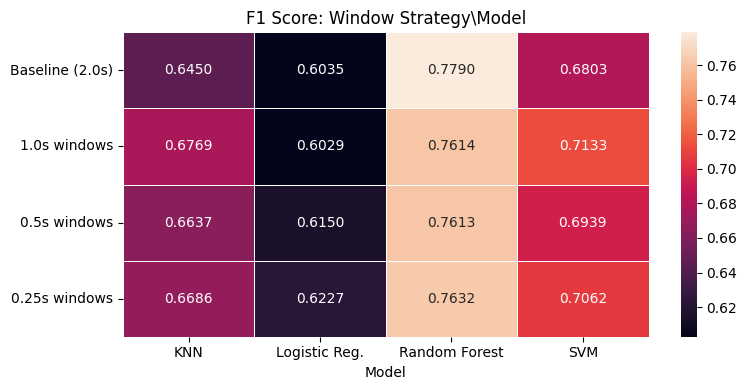

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', ax=ax, linewidths=0.5)
ax.set_title('F1 Score: Window Strategy\Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## Neural Networks

In [ ]:
import keras
from models import build_mlp, build_cnn, build_rnn
from sklearn.metrics import f1_score

def cv_evaluate_keras(build_fn, X, y_array, n_splits=5, epochs=60, batch_size=32):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_f1s = []

    for train_idx, val_idx in skf.split(X, y_array):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y_array[train_idx], y_array[val_idx]

        model = build_fn(X_train.shape[1:])
        model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_data=(X_val, y_val), verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])

        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = (y_pred_prob.squeeze() >= 0.5).astype(int)
        fold_f1s.append(f1_score(y_val, y_pred, average='weighted'))

    return fold_f1s

### Build spectrogram datasets

In [14]:
def pad_specs(specs):
    max_t = max(s.shape[1] for s in specs)
    padded = []
    for s in specs:
        if s.shape[1] < max_t:
            s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
        else:
            s = s[:, :max_t]
        padded.append(s)
    return np.array(padded)


def build_mel_full(waveforms, sr):
    specs = [extract_mel_spectrogram(y, sr) for y in waveforms]
    return pad_specs(specs)[..., np.newaxis]


def build_mel_windowed_avg(waveforms, sr, window_sec, overlap=0.5):
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    all_specs = []

    for y_wav in waveforms:
        win_specs = []
        start = 0
        while start + window_samples <= len(y_wav):
            mel = extract_mel_spectrogram(y_wav[start:start + window_samples], sr)
            win_specs.append(mel)
            start += hop_samples
        if not win_specs:
            win_specs.append(extract_mel_spectrogram(y_wav, sr))
        all_specs.append(np.mean(win_specs, axis=0))

    return pad_specs(all_specs)[..., np.newaxis]


print('Building spectrograms...')
spec_datasets = {}

spec_datasets['Full 2.0s'] = build_mel_full(waveforms, SR)
spec_datasets['Avg 0.5s'] = build_mel_windowed_avg(waveforms, SR, 0.5)
spec_datasets['Avg 0.25s'] = build_mel_windowed_avg(waveforms, SR, 0.25)

for name, data in spec_datasets.items():
    print(f'  {name}: {data.shape}')

Building spectrograms...
  Full 2.0s: (1361, 128, 87, 1)
  Avg 0.5s: (1361, 128, 22, 1)
  Avg 0.25s: (1361, 128, 11, 1)


### MLP experiment

In [ ]:
nn_results = []

print('MLP\n')
for window_name, X_np in feature_sets.items():
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_np)

    fold_f1s = cv_evaluate_keras(
        lambda shape: build_mlp(shape[0]),
        X_scaled, y, epochs=100
    )
    mean_f1, std_f1 = np.mean(fold_f1s), np.std(fold_f1s)
    nn_results.append({'Model': 'MLP', 'Data': window_name, 'F1': mean_f1, 'Std': std_f1, 'Folds': fold_f1s})
    print(f'  {window_name:20s} | {mean_f1:.4f} ± {std_f1:.4f}')

MLP

  Baseline (2.0s)      | 0.7278 ± 0.0546
  1.0s windows         | 0.7136 ± 0.0357
  0.5s windows         | 0.7201 ± 0.0347
  0.25s windows        | 0.7378 ± 0.0404


### CNN experiment

In [ ]:
print('CNN\n')
for spec_name, X in spec_datasets.items():
    fold_f1s = cv_evaluate_keras(build_cnn, X, y, epochs=120)
    mean_f1, std_f1 = np.mean(fold_f1s), np.std(fold_f1s)
    nn_results.append({'Model': 'CNN', 'Data': spec_name, 'F1': mean_f1, 'Std': std_f1, 'Folds': fold_f1s})
    print(f'  {spec_name:20s} | {mean_f1:.4f} ± {std_f1:.4f}')

CNN

  Full 2.0s            | 0.8120 ± 0.0476
  Avg 0.5s             | 0.6763 ± 0.0966
  Avg 0.25s            | 0.7928 ± 0.0436


### RNN (LSTM, because its more proper for the task) experiment

In [ ]:
print('LSTM\n')
for spec_name, X in spec_datasets.items():
    X_seq = X.squeeze(-1).transpose(0, 2, 1)
    fold_f1s = cv_evaluate_keras(build_rnn, X_seq, y, epochs=40)
    mean_f1, std_f1 = np.mean(fold_f1s), np.std(fold_f1s)
    nn_results.append({'Model': 'LSTM', 'Data': spec_name, 'F1': mean_f1, 'Std': std_f1, 'Folds': fold_f1s})
    print(f'  {spec_name:20s} | {mean_f1:.4f} ± {std_f1:.4f}')

LSTM

  Full 2.0s            | 0.4368 ± 0.0715
  Avg 0.5s             | 0.3933 ± 0.0017
  Avg 0.25s            | 0.3939 ± 0.0023


### Results

In [18]:
nn_results_df = pd.DataFrame(nn_results)

nn_pivot = nn_results_df.pivot_table(index='Data', columns='Model', values='F1')
mlp_rows = list(WINDOW_CONFIGS.keys())
spec_rows = list(spec_datasets.keys())
all_rows = mlp_rows + [r for r in spec_rows if r not in mlp_rows]
nn_pivot = nn_pivot.reindex([r for r in all_rows if r in nn_pivot.index])

display(nn_pivot.style.format('{:.4f}').background_gradient(axis=None))

Model,CNN,LSTM,MLP
Data,,,
Baseline (2.0s),nan,nan,0.7278
1.0s windows,nan,nan,0.7136
0.5s windows,nan,nan,0.7201
0.25s windows,nan,nan,0.7378
Full 2.0s,0.8120,0.4368,nan
Avg 0.5s,0.6763,0.3933,nan
Avg 0.25s,0.7928,0.3939,nan


I am kinda baffled by the results. I thought of this experiment after training the models and right now they are showing good results with 2 seconds, but in model training and a different iteration of these experiments I got much better results for the 0.5s windows and there was a worse effect when doing 0.25s windows. Right now these results seem logical, as the CNN is expected to work well with the full picture or with tiny enough fractions of it overlapped, so it can learn the details better. Usually the first 0.5 to 1 second carry the most information about the chord, so the increase in performance at 0.25s seems logical, but the 0.5 seconds seems to both omit crucial information and is not detailed enough.

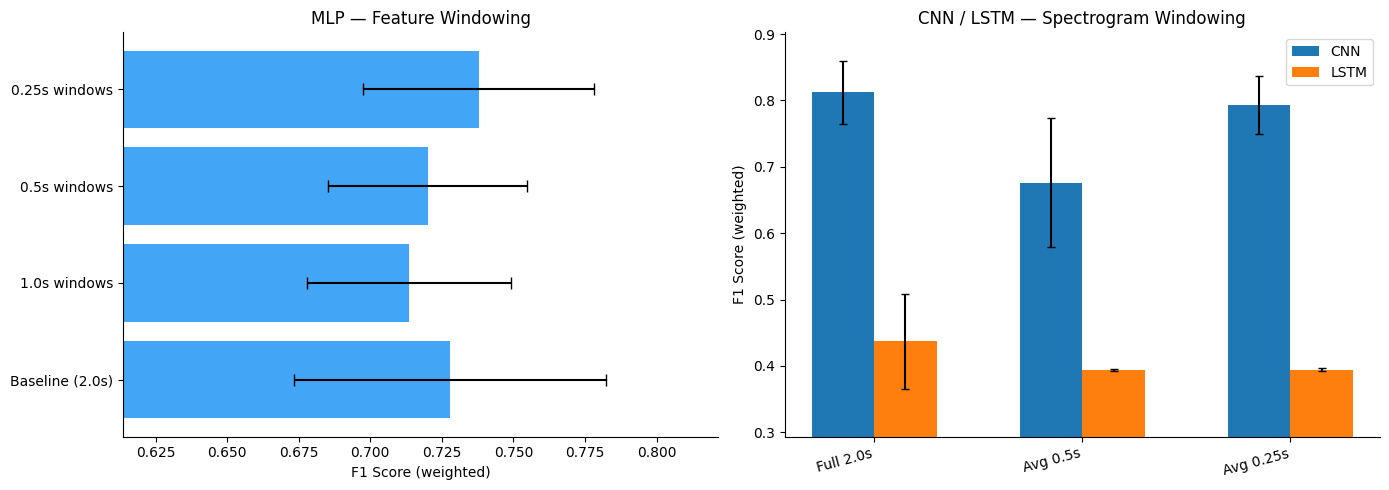

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mlp_df = nn_results_df[nn_results_df['Model'] == 'MLP']
ax = axes[0]
ax.barh(mlp_df['Data'], mlp_df['F1'], xerr=mlp_df['Std'], color='#42a5f5', capsize=4)
ax.set_xlabel('F1 Score (weighted)')
ax.set_title('MLP — Feature Windowing')
ax.set_xlim(left=max(0, mlp_df['F1'].min() - 0.1))
ax.spines[['top', 'right']].set_visible(False)

spec_df = nn_results_df[nn_results_df['Model'] != 'MLP']
ax = axes[1]
spec_strats = list(spec_datasets.keys())
nn_models = ['CNN', 'LSTM']
x = np.arange(len(spec_strats))
width = 0.3

for i, m_name in enumerate(nn_models):
    subset = spec_df[spec_df['Model'] == m_name]
    means = [subset[subset['Data'] == s]['F1'].values[0] if len(subset[subset['Data'] == s]) > 0 else 0 for s in spec_strats]
    stds = [subset[subset['Data'] == s]['Std'].values[0] if len(subset[subset['Data'] == s]) > 0 else 0 for s in spec_strats]
    ax.bar(x + i * width, means, width, yerr=stds, label=m_name, capsize=3)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(spec_strats, rotation=15, ha='right')
ax.set_ylabel('F1 Score (weighted)')
ax.set_title('CNN / LSTM — Spectrogram Windowing')
ax.set_ylim(bottom=max(0, spec_df['F1'].min() - 0.1))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

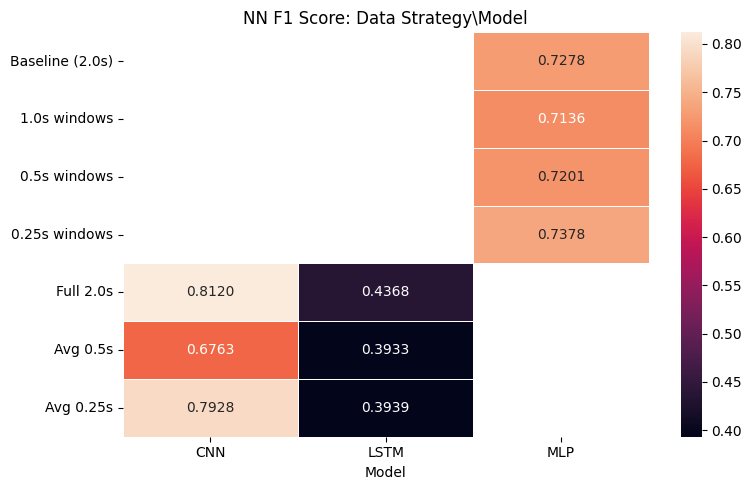

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(nn_pivot, annot=True, fmt='.4f', ax=ax, linewidths=0.5)
ax.set_title('NN F1 Score: Data Strategy\Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## All models compared

In [21]:
sklearn_df = results_df.rename(columns={'Window': 'Data'})
all_results_df = pd.concat([sklearn_df, nn_results_df], ignore_index=True)

best_overall = all_results_df.loc[all_results_df['F1'].idxmax()]
print(f'Best: {best_overall["Model"]} + {best_overall["Data"]} → {best_overall["F1"]:.4f} ± {best_overall["Std"]:.4f}')
print()

top10 = all_results_df.nlargest(10, 'F1')[['Model', 'Data', 'F1', 'Std']]
display(top10.style.format({'F1': '{:.4f}', 'Std': '{:.4f}'}).background_gradient(subset=['F1']))

Best: CNN + Full 2.0s → 0.8120 ± 0.0476



,Model,Data,F1,Std
20,CNN,Full 2.0s,0.8120,0.0476
22,CNN,Avg 0.25s,0.7928,0.0436
0,Random Forest,Baseline (2.0s),0.7790,0.0235
12,Random Forest,0.25s windows,0.7632,0.0111
4,Random Forest,1.0s windows,0.7614,0.0245
8,Random Forest,0.5s windows,0.7613,0.0240
19,MLP,0.25s windows,0.7378,0.0404
16,MLP,Baseline (2.0s),0.7278,0.0546
18,MLP,0.5s windows,0.7201,0.0347
17,MLP,1.0s windows,0.7136,0.0357


## 19. Grand heatmap

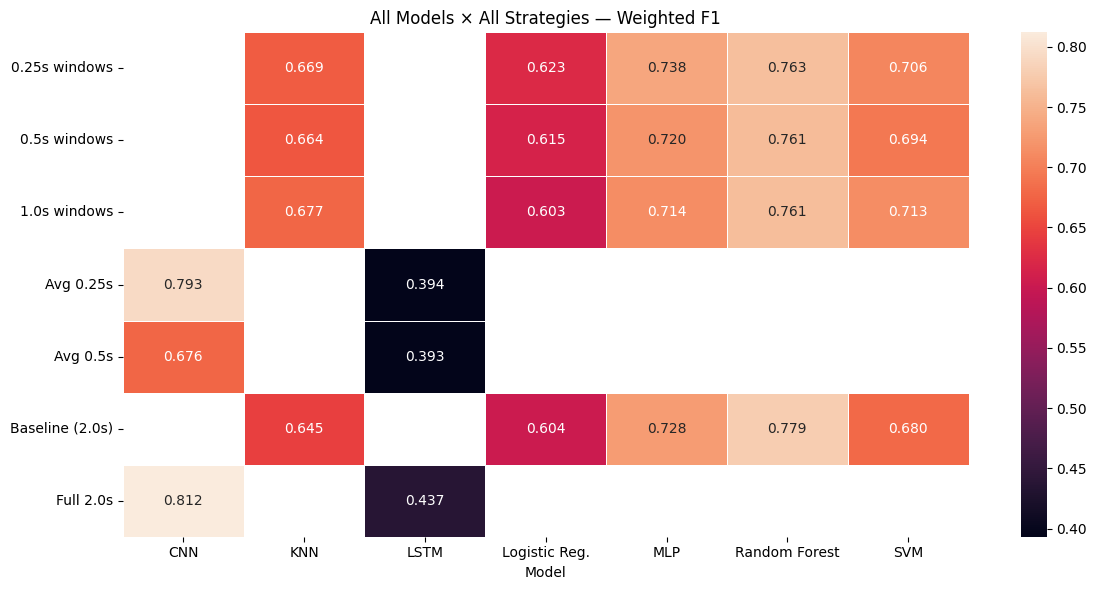

In [22]:
grand_pivot = all_results_df.pivot_table(index='Data', columns='Model', values='F1')

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(grand_pivot, annot=True, fmt='.3f', ax=ax, linewidths=0.5)
ax.set_title('All Models and All Strategies — Weighted F1')
ax.set_ylabel('')
fig.tight_layout()
plt.show()